# Sistemas Inteligentes (UFERSA)
## Projeto 1: Regressão Linear para Previsão de Produção de Energia em Usina de Ciclo Combinado
**Discente:** Nattan Ferreira Lopes  
**Docente:** Prof. Dr. Pedro Thiago Valério de Souza  

---
### Contexto do Enunciado:
> *"Uma usina termelétrica de ciclo combinado (UTCC) combina turbinas a gás e a vapor para gerar eletricidade... A potência elétrica líquida de saída (PE) é altamente sensível às condições ambientais. Neste projeto, você deve construir um modelo matemático de regressão linear múltipla para prever a produção de energia baseando-se em sensores ambientais..."*

**Variáveis do Dataset (UCI CCPP):**
- **AT** (*Ambient Temperature*): Temperatura em °C.
- **V** (*Exhaust Vacuum*): Vácuo de escape em cm Hg.
- **AP** (*Ambient Pressure*): Pressão atmosférica em mbar.
- **RH** (*Relative Humidity*): Umidade relativa em percentagem.
- **PE** (*Net Hourly Electrical Energy Output*): Variável alvo dependente em MW (MegaWatts).


In [ ]:
# Importação das bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


## Passo 1: Carregamento dos Dados e Pré-Processamento Inicial
> **Enunciado:** *"Realize o pré-processamento dos dados, incluindo a normalização ou padronização das variáveis independentes, tratamento de valores ausentes e divisão dos dados em conjuntos de treino e teste."*


In [ ]:
# Carregando o dataset CCPP
try:
    df = pd.read_csv('../data/CCPP/ccpp_data.csv')
except FileNotFoundError:
    df = pd.read_csv('data/CCPP/ccpp_data.csv')

print(f"Total de linhas (amostras): {df.shape[0]}")
print(f"Total de colunas (variáveis): {df.shape[1]}\n")

# Tratamento de valores ausentes
print("Contagem de valores ausentes por coluna:")
print(df.isnull().sum())

# Visualizando as primeiras linhas
df.head()


Total de linhas (amostras): 9568
Total de colunas (variáveis): 5

Contagem de valores ausentes por coluna:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## Tarefa 1: Correlação com a Variável Dependente (PE)
> **Enunciado da Tarefa 1:**  
> *"1. Calcule a correlação entre as variáveis independentes (AT, V, AP, RH) e a variável dependente (PE). Quais variáveis parecem ter maior influência na produção de energia?"*


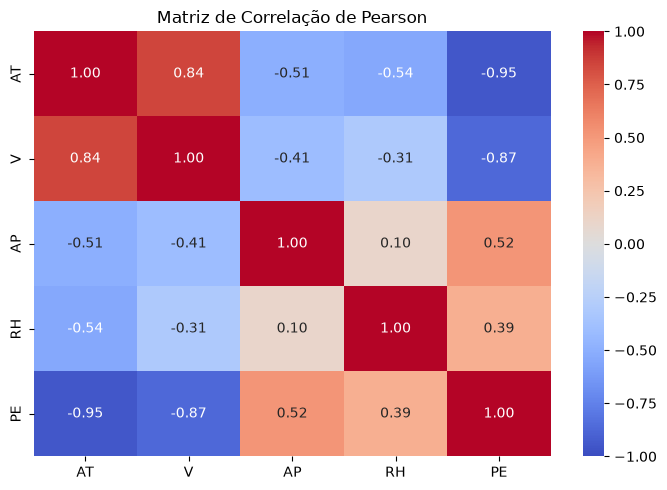

Correlação de cada variável com a saída de energia (PE):
AT   -0.948128
V    -0.869780
RH    0.389794
AP    0.518429
PE    1.000000
Name: PE, dtype: float64


In [ ]:
# Matriz de correlação de Pearson
corr = df.corr()

# Gráfico de calor (Heatmap)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title("Matriz de Correlação de Pearson")
plt.tight_layout()
plt.show()

# Correlações isoladas com a variável alvo PE
print("Correlação de cada variável com a saída de energia (PE):")
print(corr['PE'].sort_values())


### Resposta da Tarefa 1:
As variáveis que possuem **maior influência na produção de energia são a Temperatura Ambiente (AT) e o Vácuo de Escape (V)**:
- **AT (Temperatura):** correlação de **-0.95** (relação negativa fortíssima). Quando a temperatura sobe, a densidade do ar diminui, o que reduz o fluxo de massa na turbina a gás e derruba a potência gerada.
- **V (Vácuo):** correlação de **-0.87** (relação negativa muito forte). Quando a pressão de escape aumenta (menor vácuo), a eficiência do ciclo a vapor cai.
- **AP (Pressão):** correlação positiva moderada (**+0.52**).
- **RH (Umidade):** correlação positiva moderada (**+0.39**).


## Tarefa 2: Correlação entre as Variáveis Independentes e Multicolinearidade
> **Enunciado da Tarefa 2:**  
> *"2. Calcule a correlação entre as variáveis independentes (AT, V, AP, RH) entre si. Existe alguma relação forte entre elas? Se sim, isso pode indicar multicolinearidade."*


In [ ]:
# Extraindo apenas as variáveis independentes
indep_corr = df[['AT', 'V', 'AP', 'RH']].corr()
print("Correlações entre as variáveis independentes:")
print(indep_corr.round(4))


Correlações entre as variáveis independentes:
        AT       V      AP      RH
AT  1.0000  0.8441 -0.5075 -0.5425
V   0.8441  1.0000 -0.4135 -0.3122
AP -0.5075 -0.4135  1.0000  0.0996
RH -0.5425 -0.3122  0.0996  1.0000


### Resposta da Tarefa 2:
- **Sim, existe uma relação muito forte entre AT (Temperatura) e V (Vácuo), com correlação de 0.84.**
- As demais variáveis têm correlações menores (todas abaixo de 0.55).
- **Isso indica multicolinearidade?** Sim, essa alta correlação de **0.84** entre AT e V indica **potencial multicolinearidade**. Na física da usina, dias mais quentes aumentam a temperatura da água de resfriamento do condensador, afetando diretamente o vácuo de escape. Portanto, ambas trazem informações parcialmente parecidas sobre o estado térmico da planta.


## Tarefa 3: Construção do Modelo e Divisão Treino/Teste
> **Enunciado da Tarefa 3:**  
> *"3. Construa um modelo de regressão linear múltipla utilizando as variáveis independentes (AT, V, AP, RH) para prever a variável dependente (PE). Divida os dados em treino (80%) e teste (20%)."*


In [ ]:
# 1. Separando X e y
X = df[['AT', 'V', 'AP', 'RH']]
y = df['PE']

# 2. Divisão em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 3. Padronização dos atributos (Z-score)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Amostras de treino: {X_train.shape[0]}")
print(f"Amostras de teste:  {X_test.shape[0]}")

# 4. Treinando o Modelo de Regressão Linear Múltipla
modelo = LinearRegression()
modelo.fit(X_train_scaled, y_train)

# Coeficientes aprendidos
df_pesos = pd.DataFrame({
    'Variável': ['AT', 'V', 'AP', 'RH'],
    'Coeficiente (Peso)': modelo.coef_
})

print(f"\nIntercepto (Bias - θ0): {modelo.intercept_:.2f}")
print(df_pesos.to_string(index=False))


Amostras de treino: 7654
Amostras de teste:  1914

Intercepto (Bias - θ0): 454.43
Variável  Coeficiente (Peso)
      AT          -14.763927
       V           -2.949632
      AP            0.369780
      RH           -2.312196


## Tarefa 4: Avaliação do Modelo e Adequação
> **Enunciado da Tarefa 4:**  
> *"4. Avalie o desempenho do modelo utilizando métricas como R², RMSE e MAE. O modelo é adequado para prever a produção de energia? Justifique sua resposta."*


In [ ]:
# Previsões no conjunto de teste
y_pred = modelo.predict(X_test_scaled)

# Cálculo das métricas de desempenho
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("--- Métricas de Avaliação no Conjunto de Teste ---")
print(f"R²   (Coeficiente de Determinação): {r2:.4f}  ({r2*100:.2f}%)")
print(f"RMSE (Raiz do Erro Quadrático):     {rmse:.4f} MW")
print(f"MAE  (Erro Absoluto Médio):         {mae:.4f} MW")


--- Métricas de Avaliação no Conjunto de Teste ---
R²   (Coeficiente de Determinação): 0.9301  (93.01%)
RMSE (Raiz do Erro Quadrático):     4.5026 MW
MAE  (Erro Absoluto Médio):         3.5959 MW


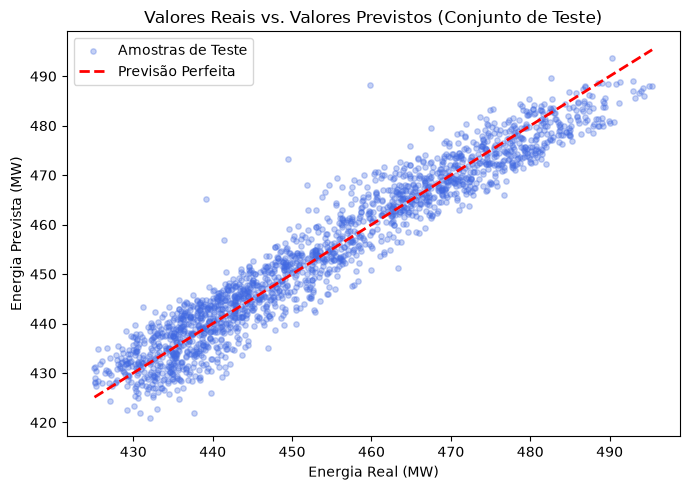

In [ ]:
# Gráfico de Valores Reais vs. Valores Previstos
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='royalblue', alpha=0.3, s=15, label='Amostras de Teste')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Previsão Perfeita')
plt.title("Valores Reais vs. Valores Previstos (Conjunto de Teste)")
plt.xlabel("Energia Real (MW)")
plt.ylabel("Energia Prevista (MW)")
plt.legend()
plt.tight_layout()
plt.show()


### Resposta da Tarefa 4: O modelo é adequado para prever a produção de energia?

**Sim, o modelo é altamente adequado.**
- **R² de 0.9301 (93%):** O modelo consegue explicar cerca de 93% de toda a variação da produção de energia da usina apenas utilizando os 4 sensores ambientais.
- **Erro médio (MAE de 3.60 MW e RMSE de 4.50 MW):** A usina produz em média 454 MW. Um erro de 3.6 MW representa um erro relativo menor que **0,8%**, o que é uma precisão excelente para operação industrial e despacho energético no mundo real.
